# Thommes et al. (2008): eccentricity-damping timescale

This notebook reproduces the tidal eccentricity-damping timescale used in Thommes, Nagasawa & Lin (2008), equation (1):

$$\tau_{e,\mathrm{tide}} \simeq \left(\frac{M_\star}{M_p}\right) \left(\frac{M_\star}{\Sigma_g a^2}\right) \left(\frac{H}{a}\right)^4 \Omega_k^{-1}.$$

The calculation uses `Gas_MigrationIntegrator.tau_wave()`, which has the same functional form. Aerodynamic planetesimal drag and the Cresswell & Nelson (2008) correction are deliberately excluded. The selected masses are $10^{-6}$-$10^{-3}\,M_\oplus$; applying the tidal formula at these small masses should be regarded as an extrapolation.

In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / 'src' / 'accrediff').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate the AccreDiff repository root')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from accrediff.gas_migration import Gas_ModelConfig, Gas_build_model

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 11, 'axes.linewidth': 1.2,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True, 'figure.dpi': 180,
})

## 1. Paper disk model

Thommes et al. adopt

$$\Sigma_g=2000\left(\frac{r}{1\,\mathrm{AU}}\right)^{-1}\exp(-t/\tau_n)\;\mathrm{g\,cm^{-2}}, \qquad \tau_n=5\,\mathrm{Myr},$$

and

$$H=0.05\left(\frac{r}{1\,\mathrm{AU}}\right)^{5/4}\mathrm{AU}.$$

In [2]:
paper_cfg = Gas_ModelConfig(
    Mstar=1.0,
    particle_mass_mearth=1.0,
    Sigma0_cgs=2000.0,
    a_alpha1=0.0,
    a_alpha2=1.0,
    def_h_1=0.05,
    beta=0.25,
    tau_decay_myr=5.0,
)

reference_model = Gas_build_model(paper_cfg)
disk = reference_model['disk']
units = reference_model['units']

def build_integrator(mass_mearth):
    return Gas_build_model(replace(
        paper_cfg, particle_mass_mearth=float(mass_mearth)
    ))['integrator']

def thommes_tau_year(mass_mearth, a_au, time_myr):
    integrator = build_integrator(mass_mearth)
    t_code = units.myr_to_code(time_myr)
    tau_code = integrator.tau_wave(t_code, np.asarray(a_au, dtype=float))
    return np.asarray(tau_code) * units.YEAR_PER_CODE

r_check = np.array([0.5, 1.0, 2.0, 3.0])
disk_check = pd.DataFrame({
    'a_AU': r_check,
    'Sigma_g_t0_g_cm2': disk.sigma_cgs(r_check, units.myr_to_code(0.0)),
    'H_AU': disk.scale_height(r_check),
    'H_over_a': disk.aspect_ratio(r_check),
})
disk_check.round(7)

,a_AU,Sigma_g_t0_g_cm2,H_AU,H_over_a
0,0.5,4000.000000,0.021022,0.042045
1,1.0,2000.000000,0.050000,0.050000
2,2.0,1000.000000,0.118921,0.059460
3,3.0,666.666667,0.197411,0.065804


## 2. Equations (1) and (3): eccentricity and semimajor-axis damping

At fixed position and disk time, equation (1) gives $\tau_{e,\rm tide}$, which is independent of eccentricity in this linear prescription. Equation (3) gives $\tau_{a,\rm damp}=a/|\dot a|=(1-e^2)\tau_{e,\rm tide}/(2e^2)$. Both are shown together below: orange is equation (1), while the blue curves are equation (3) for different SSR-excited eccentricities.

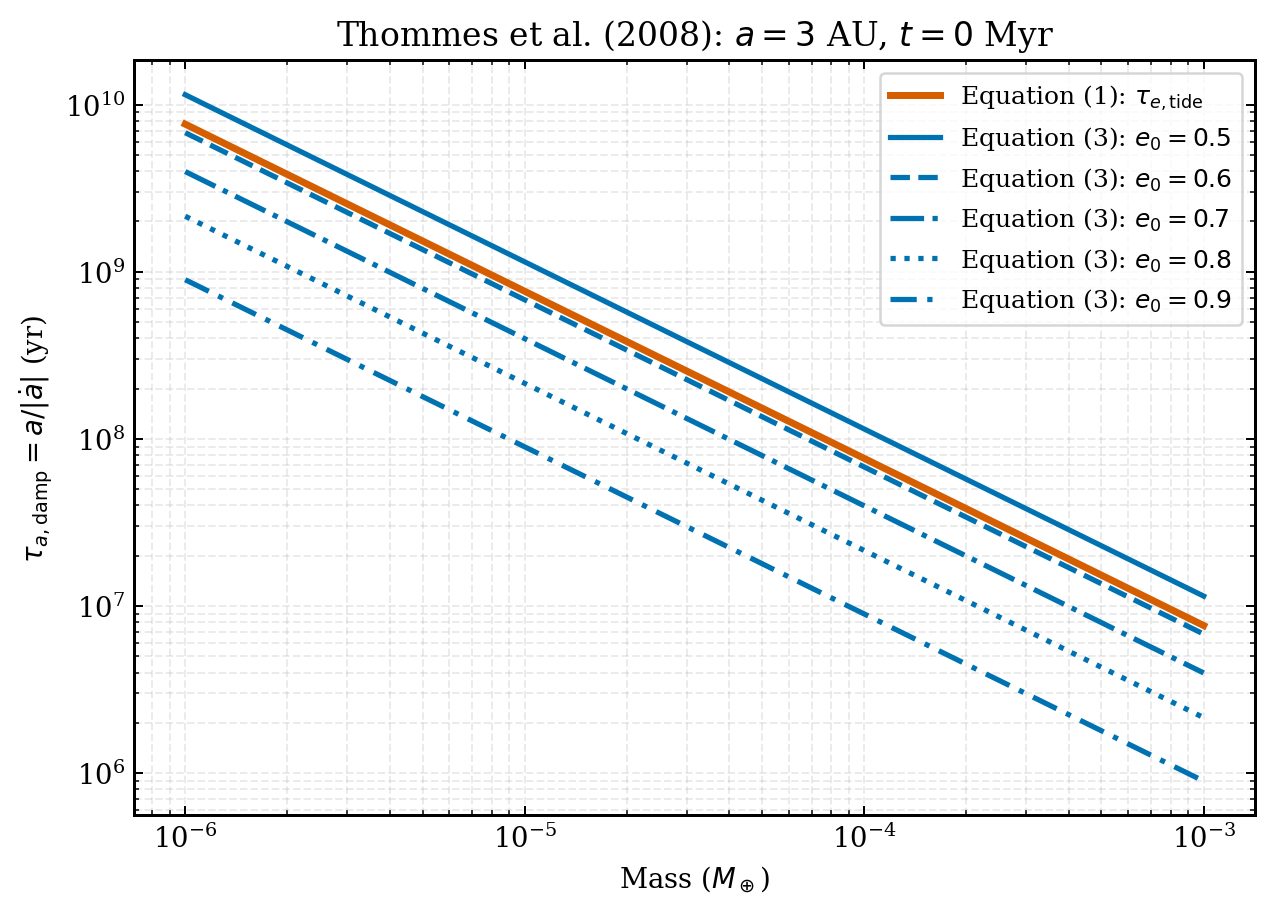

In [3]:
# ---------------- User-adjustable plotting parameters ----------------
A_FIXED_AU = 3.0
TIME_MYR = 0.0
MASS_MIN_MEARTH = 1e-6
MASS_MAX_MEARTH = 1e-3
ECCENTRICITIES = (0.5, 0.6, 0.7, 0.8, 0.9)
N_MASS = 400
# --------------------------------------------------------------------

mass_grid = np.logspace(
    np.log10(MASS_MIN_MEARTH), np.log10(MASS_MAX_MEARTH), N_MASS
)
line_styles = ('-', '--', '-.', ':', (0, (5, 2, 1, 2)))

def equation3_timescale_year(mass_mearth, eccentricity, a_au=A_FIXED_AU, time_myr=TIME_MYR):
    tau_e = np.asarray([
        thommes_tau_year(mass, a_au, time_myr) for mass in np.atleast_1d(mass_mearth)
    ], dtype=float)
    return (1.0 - eccentricity**2) / (2.0 * eccentricity**2) * tau_e

fig, ax = plt.subplots(figsize=(7.2, 5.2))
tau_e_grid = np.asarray([
    thommes_tau_year(mass, A_FIXED_AU, TIME_MYR) for mass in mass_grid
])
ax.loglog(
    mass_grid, tau_e_grid, color='#D55E00', lw=2.8,
    label=r'Equation (1): $\tau_{e,\rm tide}$', zorder=3,
)
for eccentricity, linestyle in zip(ECCENTRICITIES, line_styles):
    ax.loglog(
        mass_grid, equation3_timescale_year(mass_grid, eccentricity),
        color='#0072B2', ls=linestyle, lw=2.1,
        label=fr'Equation (3): $e_0={eccentricity:g}$',
    )
ax.set(
    xlabel=r'Mass ($M_\oplus$)',
    ylabel=r'$\tau_{a,\rm damp}=a/|\dot a|$ (yr)',
    title=fr'Thommes et al. (2008): $a={A_FIXED_AU:g}$ AU, $t={TIME_MYR:g}$ Myr',
)
ax.grid(which='both', alpha=0.25, ls='--')
ax.legend(frameon=True, fontsize=10)
fig.tight_layout()
plt.show()

## 3. Numerical values

Representative values at the four mass scales of interest. The table includes equation (1) and the equation (3) results for every selected eccentricity.

In [4]:
reference_masses = (1e-6, 1e-5, 1e-4, 1e-3)
values = pd.DataFrame(
    {'tau_e_eq1_yr': [thommes_tau_year(m, A_FIXED_AU, TIME_MYR) for m in reference_masses],
     **{fr'tau_a_eq3_e={e:g}_yr': equation3_timescale_year(reference_masses, e)
        for e in ECCENTRICITIES}},
    index=pd.Index(reference_masses, name='mass_Mearth'),
)
assert all(np.all(np.diff(values[column]) < 0) for column in values.columns)
values

,tau_e_eq1_yr,tau_a_eq3_e=0.5_yr,tau_a_eq3_e=0.6_yr,tau_a_eq3_e=0.7_yr,tau_a_eq3_e=0.8_yr,tau_a_eq3_e=0.9_yr
mass_Mearth,,,,,,
0.000001,7.645294e+09,1.146794e+10,6.795817e+09,3.978674e+09,2.150239e+09,8.966703e+08
0.000010,7.645294e+08,1.146794e+09,6.795817e+08,3.978674e+08,2.150239e+08,8.966703e+07
0.000100,7.645294e+07,1.146794e+08,6.795817e+07,3.978674e+07,2.150239e+07,8.966703e+06
0.001000,7.645294e+06,1.146794e+07,6.795817e+06,3.978674e+06,2.150239e+06,8.966703e+05


## Scope

This notebook compares the instantaneous eccentricity-damping timescale from equation (1) with the damping-driven semimajor-axis timescale from equation (3), at a configurable fixed position and disk time. It does not calculate the SSR excitation itself.

## Interpretation

Larger SSR-excited eccentricity produces a much shorter damping-driven migration timescale because $\tau_{a,\rm damp}\propto(1-e^2)/e^2$. The two timescales are equal at $e=1/\sqrt{3}\simeq0.577$; above this eccentricity equation (3) gives a shorter timescale than equation (1). At fixed $a$ and $t$, both timescales scale as $M_p^{-1}$.

In [5]:
# No additional figure is needed here; the main result is the mass-timescale plot above.
print(f'Configuration: a={A_FIXED_AU:g} AU, t={TIME_MYR:g} Myr, e={ECCENTRICITIES}')

Configuration: a=3 AU, t=0 Myr, e=(0.5, 0.6, 0.7, 0.8, 0.9)


## 4. Eccentricity damping: aerodynamic gas drag versus Type I

This section compares the same quantity, $\tau_e=e/|\dot e|$, for two separate mechanisms. The left panel uses the orbit-averaged aerodynamic drag acceleration for its own configurable eccentricity list. Because $\tau_e$ is formally $0/0$ at exactly $e=0$, the circular curve is evaluated as the small-eccentricity limit at `CIRCULAR_LIMIT_E`. The right panel uses the uncorrected Type-I tidal damping timescale from equation (1), so it is independent of eccentricity. The particle radius is inferred from its mass assuming $\rho_p=3\,\mathrm{g\,cm^{-3}}$.

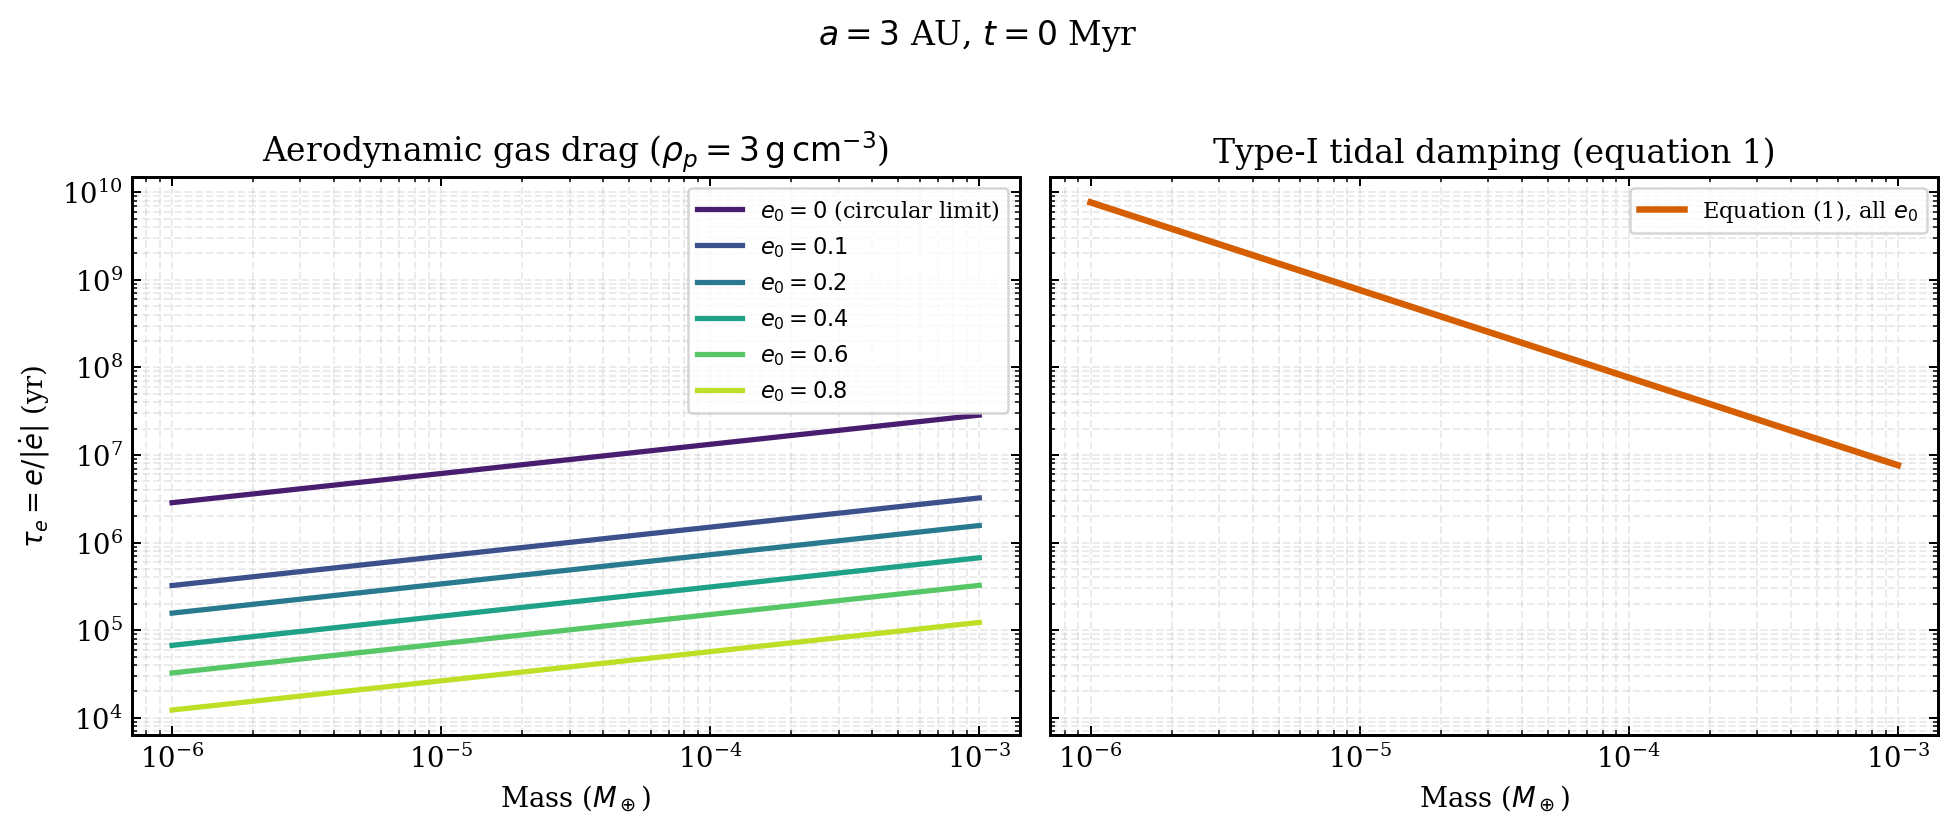

In [6]:
# ---------------- Additional adjustable parameters ----------------
SOLID_DENSITY_CGS = 3.0
DRAG_COEFFICIENT = 0.5
ORBIT_SAMPLES = 256
GAS_DRAG_ECCENTRICITIES = (0.0, 0.1, 0.2, 0.4, 0.6, 0.8)
CIRCULAR_LIMIT_E = 1e-4
# ------------------------------------------------------------------

gas_drag_module_dir = PROJECT_ROOT / 'examples' / 'Expansion_module' / 'GasDrag_Type1'
if str(gas_drag_module_dir) not in sys.path:
    sys.path.insert(0, str(gas_drag_module_dir))

from paper_fig2_disk import GasMigrationDiskAdapter
from paper_fig2_drag import AerodynamicDrag, GasFlowPolicy, MEARTH_G, Planetesimal
from paper_fig2_orbit_average import orbit_averaged_rates

drag_disk = GasMigrationDiskAdapter(disk, units)
tau_e_drag_year = {e: np.empty_like(mass_grid) for e in GAS_DRAG_ECCENTRICITIES}

for mass_index, mass_mearth in enumerate(mass_grid):
    mass_g = mass_mearth * MEARTH_G
    radius_cm = (3.0 * mass_g / (4.0 * np.pi * SOLID_DENSITY_CGS))**(1.0 / 3.0)
    body = Planetesimal(
        radius_km=radius_cm / 1e5,
        solid_density_cgs=SOLID_DENSITY_CGS,
    )
    drag_force = AerodynamicDrag(
        planetesimal=body,
        flow=GasFlowPolicy(convention='genga_style'),
        law='genga_style',
        drag_coefficient=DRAG_COEFFICIENT,
    )
    for eccentricity in GAS_DRAG_ECCENTRICITIES:
        evaluation_e = CIRCULAR_LIMIT_E if eccentricity == 0.0 else eccentricity
        rates = orbit_averaged_rates(
            A_FIXED_AU, evaluation_e, TIME_MYR, drag_disk, drag_force,
            n_samples=ORBIT_SAMPLES,
        )
        de_dt_per_myr = rates.de_dt_per_myr
        tau_e_drag_year[eccentricity][mass_index] = (
            evaluation_e / abs(de_dt_per_myr) * 1e6
            if de_dt_per_myr != 0.0 else np.inf
        )

tau_e_type1_year = np.asarray([
    thommes_tau_year(mass, A_FIXED_AU, TIME_MYR) for mass in mass_grid
])

colors = plt.cm.viridis(np.linspace(0.08, 0.9, len(GAS_DRAG_ECCENTRICITIES)))
fig, (ax_drag, ax_type1) = plt.subplots(1, 2, figsize=(11.0, 4.5), sharex=True, sharey=True)
for eccentricity, color in zip(GAS_DRAG_ECCENTRICITIES, colors):
    curve_label = (fr'$e_0={eccentricity:g}$ (circular limit)'
                   if eccentricity == 0.0 else fr'$e_0={eccentricity:g}$')
    ax_drag.loglog(
        mass_grid, tau_e_drag_year[eccentricity], color=color, lw=2.1,
        label=curve_label,
    )
ax_type1.loglog(
    mass_grid, tau_e_type1_year, color='#D55E00', lw=2.6,
    label=r'Equation (1), all $e_0$',
)

for axis in (ax_drag, ax_type1):
    axis.set_xlabel(r'Mass ($M_\oplus$)')
    axis.grid(which='both', alpha=0.25, ls='--')
    axis.legend(frameon=True, fontsize=9)
ax_drag.set_ylabel(r'$\tau_e=e/|\dot e|$ (yr)')
ax_drag.set_title(r'Aerodynamic gas drag ($\rho_p=3\,\mathrm{g\,cm^{-3}}$)')
ax_type1.set_title('Type-I tidal damping (equation 1)')
fig.suptitle(fr'$a={A_FIXED_AU:g}$ AU, $t={TIME_MYR:g}$ Myr', y=1.02)
fig.tight_layout()
plt.show()

In [7]:
# Representative numerical values for direct comparison.
sample_indices = [int(np.argmin(abs(mass_grid - mass))) for mass in reference_masses]
damping_values = pd.DataFrame(
    {
        'tau_e_typeI_yr': tau_e_type1_year[sample_indices],
        **{fr'tau_e_gas_e={e:g}_yr': tau_e_drag_year[e][sample_indices]
           for e in GAS_DRAG_ECCENTRICITIES},
    },
    index=pd.Index(mass_grid[sample_indices], name='mass_Mearth'),
)
damping_values

,tau_e_typeI_yr,tau_e_gas_e=0_yr,tau_e_gas_e=0.1_yr,tau_e_gas_e=0.2_yr,tau_e_gas_e=0.4_yr,tau_e_gas_e=0.6_yr,tau_e_gas_e=0.8_yr
mass_Mearth,,,,,,,
0.000001,7.645294e+09,2.852097e+06,3.233858e+05,1.566484e+05,67088.154610,32485.412056,12260.845110
0.000010,7.645294e+08,6.144656e+06,6.967136e+05,3.374888e+05,144537.047583,69987.698654,26415.190035
0.000100,7.645294e+07,1.323826e+07,1.501024e+06,7.270977e+05,311395.629308,150783.925855,56909.801755
0.001000,7.645294e+06,2.852097e+07,3.233858e+06,1.566484e+06,670881.546105,324854.120561,122608.451104
